In [8]:
# 코랩 환경 확인. CAT-Net 은 좀 옛날거라서

import platform
from importlib.metadata import version, PackageNotFoundError

import torch

print("Python:", platform.python_version())

for package in ("torch", "torchvision", "numpy", "Pillow", "jpegio"):
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: 설치되지 않음.")

print("PyTorch CUDA:", torch.version.cuda)
print("GPU 사용 가능:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16
torch: 2.14.1+cu130
torchvision: 0.29.1+cu130
numpy: 2.4.6
Pillow: 11.3.0
jpegio: 설치되지 않음.
PyTorch CUDA: 13.0
GPU 사용 가능: True
GPU: NVIDIA L4


In [9]:
# 모듈 로드
%pip install pyjpegio

In [10]:
from importlib.metadata import version
import jpegio

print("pyjpegio:", version("pyjpegio"))
print("jpegio 경로:", jpegio.__file__)
print("JPEG 읽기 함수:", callable(jpegio.read))

pyjpegio: 0.3.0
jpegio 경로: /usr/local/lib/python3.13/dist-packages/jpegio/__init__.py
JPEG 읽기 함수: True


## 사전학습 CAT-Net 가중치 준비
공식 배포처에서 다운받음.
사용 모델: `CAT_full_v2.pth.tar`

In [11]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [14]:
project_root = Path("/content/drive/MyDrive/AI_Forensics/project")
weight_source = project_root / "models/pretrained/catnet/CAT_full_v2.pth.tar"
weight_path = Path("/content/CAT_full_v2.pth.tar")

if not weight_source.is_file():
    raise FileNotFoundError(f"Drive에 가중치 파일읎음: {weight_source}")

print("Drive 가중치:", weight_source)
print("런타임 복사 위치:", weight_path)

Drive 가중치: /content/drive/MyDrive/AI_Forensics/project/models/pretrained/catnet/CAT_full_v2.pth.tar
런타임 복사 위치: /content/CAT_full_v2.pth.tar


In [15]:
## 런타임에 복사하고, 대조하자.

import hashlib
import shutil

with weight_source.open("rb") as file:
    source_hash = hashlib.file_digest(file, "sha256").hexdigest()

shutil.copyfile(weight_source, weight_path)

with weight_path.open("rb") as file:
    copied_hash = hashlib.file_digest(file, "sha256").hexdigest()

if source_hash != copied_hash:
    raise ValueError("Drive 원본과 복사본의 SHA-256이 일치해야 함.")

weight_size = weight_path.stat().st_size

print("가중치 파일:", weight_path.name)
print("파일 크기(bytes):", weight_size)
print("파일 크기(GiB):", round(weight_size / 1024**3, 3))
print("SHA-256:", copied_hash)
print("원본과 복사본 일치:", source_hash == copied_hash)

가중치 파일: CAT_full_v2.pth.tar
파일 크기(bytes): 915503873
파일 크기(GiB): 0.853
SHA-256: f82aaafdd1142775231feedcea0bb7027f7370561d9e8d107465454001865989
원본과 복사본 일치: True


## CAT-Net 공식 코드 준비
**CAT_Net 클래스가 여기에 있음**

In [16]:
import subprocess

catnet_root = Path("/content/CAT-Net")
catnet_url = "https://github.com/mjkwon2021/CAT-Net.git"

# 깃 클론
if not catnet_root.exists():
    subprocess.run(["git", "clone", catnet_url, str(catnet_root)], check=True)

# 버전 고정인데, 사실 저장소 업데이트가 몇년전이긴 함
result = subprocess.run(
    ["git", "-C", str(catnet_root), "rev-parse", "HEAD"],
    check=True, capture_output=True, text=True
)
catnet_commit = result.stdout.strip()

print("공식 코드 위치:", catnet_root)
print("코드 커밋:", catnet_commit)

공식 코드 위치: /content/CAT-Net
코드 커밋: 5eb85900b0e72423c95a8d41bc835b86c8671f8a


In [19]:
required_files = (
    "lib/models/network_CAT.py",
    "experiments/CAT_full.yaml",
    "Splicing/data/AbstractDataset.py",
)

for relative in required_files:
    if not (catnet_root / relative).is_file():
        raise FileNotFoundError(f"파일 확인 필요: {relative}")
    print(f"파일 확인: {relative}" )

파일 확인: lib/models/network_CAT.py
파일 확인: experiments/CAT_full.yaml
파일 확인: Splicing/data/AbstractDataset.py


## 위에 까지 해서 사전모델 준비 끝
공통 함수로 만들어놔야하나 좀 번거롭네

## 모델을 로드해보자.

In [21]:
%pip install yacs PyYAML

from importlib.metadata import version
import yacs.config
import yaml

print("yacs:", version("yacs"))
print("PyYAML:", version("PyYAML"))

yacs: 0.1.8
PyYAML: 6.0.3


In [23]:
import sys
import torch

# 검색 경로 추가
if str(catnet_root) not in sys.path:
    sys.path.insert(0, str(catnet_root))

from lib.config import config
from lib.models import network_CAT

print("모델 코드 위치:", network_CAT.__file__)

모델 코드 위치: /content/CAT-Net/lib/models/network_CAT.py


In [24]:
cfg = config.clone()
cfg.defrost()
cfg.merge_from_file(str(catnet_root / "experiments/CAT_full.yaml"))
cfg.freeze()

model = network_CAT.CAT_Net(cfg)

parameter_count = sum(parameter.numel() for parameter in model.parameters())

print("모델:", type(model).__name__)
print("출력 클래스 수:", cfg.DATASET.NUM_CLASSES)
print("파라미터 수:", f"{parameter_count:,}")

모델: CAT_Net
출력 클래스 수: 2
파라미터 수: 114,263,810


### 사전 가중치 적용

In [ ]:

checkpoint = torch.load(weight_path, map_location="cpu", weights_only=False)

print("checkpoint:", list(checkpoint.keys()))

checkpoint: ['epoch', 'best_p_mIoU', 'state_dict', 'optimizer']


In [30]:
load_result = model.load_state_dict(checkpoint["state_dict"], strict=True)

print("누락된 키:", load_result.missing_keys)
print("예상하지 않은 키:", load_result.unexpected_keys)
print("체크포인트 epoch:", checkpoint.get("epoch"))

del checkpoint

누락된 키: []
예상하지 않은 키: []
체크포인트 epoch: 196


In [32]:
device = torch.device("cuda")
model = model.to(device)
model.eval()

print("device:", next(model.parameters()).device)
print("is test?:", not model.training)

device: cuda:0
is test?: True


## 실제 이미지, catnet 입력 확인
정답 마스크는 공통합수로, 모델 입력은 catnet에서 사용된 공식 전처리로 읽는다.

In [33]:
%pip install torch-dct opencv-python tqdm matplotlib

In [34]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from scripts import datasets, preprocessing

split_path = project_root / "scripts/splits/autosplice_seed42.csv"
archive_path = project_root.parent / "datasets/AutoSplice/AutoSplice.zip"
data_root = Path("/content/datasets")

archive_hash = "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36"

# 공통함수로 데이터 로드
datasets.prepare_dataset_zip(archive_path, Path("/content/AutoSplice.zip"), data_root, archive_hash)

AutoSplice ZIP SHA-256 확인 및 압축 해제 완료


PosixPath('/content/datasets')

원본 ID: 39406
분할: train
이미지: 39406_0.jpg
마스크: 39406_mask.png
RGB: (256, 374, 3) uint8
정답 마스크: (256, 374) [0 1]
조작 영역 비율: 0.0848199364973262


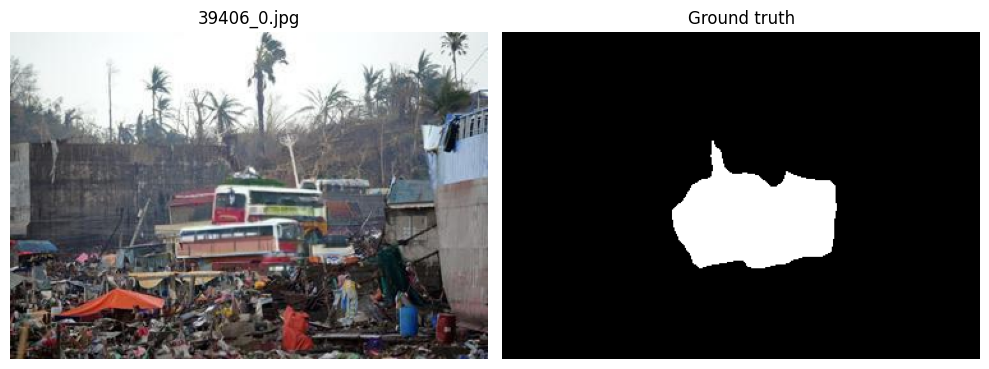

In [35]:
records = datasets.autosplice_records(data_root / "AutoSplice", split_path, quality=100)
train_records = [record for record in records if record["split"] == "train" and record["kind"] == "manipulated"]
train_records = sorted(train_records, key=lambda record: record["image_path"].name)

sample = train_records[0]
image_path = sample["image_path"]
mask_path = sample["mask_path"]

rgb = preprocessing.load_rgb(image_path)
mask = preprocessing.load_binary_mask(mask_path, foreground_value=255)
original_h, original_w = mask.shape


print("원본 ID:", sample["original_id"])
print("분할:", sample["split"])
print("이미지:", image_path.name)
print("마스크:", mask_path.name)
print("RGB:", rgb.shape, rgb.dtype)
print("정답 마스크:", mask.shape, np.unique(mask))
print("조작 영역 비율:", float(mask.mean()))


# 출력
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(rgb)
axes[0].set_title(image_path.name)
axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground truth")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [36]:
import cv2
import torch_dct
from importlib.metadata import version
from Splicing.data.dataset_arbitrary import arbitrary

catnet_dataset = arbitrary(
    crop_size=None, grid_crop=True,
    blocks=("RGB", "DCTvol", "qtable"),
    DCT_channels=1, tamp_list=str(image_path), read_from_jpeg=True
)

input_tensor, placeholder_mask, qtable = catnet_dataset.get_tamp(0)

x = input_tensor.unsqueeze(0)
q = qtable.unsqueeze(0)

rgb_tensor = input_tensor[:3]
dct_volume = input_tensor[3:]


print("원본 크기(H, W):", (original_h, original_w))
print("전처리 후 크기(H, W):", tuple(input_tensor.shape[-2:]))
print("모델 입력 x:", tuple(x.shape), x.dtype)
print("qauntize 테이블 q:", tuple(q.shape), q.dtype)
print("RGB 범위:", rgb_tensor.min().item(), rgb_tensor.max().item())
print("DCT volume 값:", torch.unique(dct_volume).tolist())
print("DCT 위치별 채널 합이 1:", bool(torch.all(dct_volume.sum(dim=0) == 1)))
print("quantize 테이블:")
print(qtable[0])

원본 크기(H, W): (256, 374)
전처리 후 크기(H, W): (256, 376)
모델 입력 x: (1, 24, 256, 376) torch.float32
qauntize 테이블 q: (1, 1, 8, 8) torch.float32
RGB 범위: -1.0 1.0
DCT volume 값: [0.0, 1.0]
DCT 위치별 채널 합이 1: True
quantize 테이블:
tensor([[1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1.]])


/content/CAT-Net/Splicing/data/AbstractDataset.py:163: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  t_DCT_coef = torch.tensor(DCT_coef, dtype=torch.float)  # final (but used below)


## 이제 진짜 추론을 해보자.
- Cat-Net의 출력 점수를 전처리 입력 크기로 복원한 뒤 조작 확률 변환까지
- 시각화할 때는 패딩 제거
- 이번에는 임계값 0.5를 사용

In [37]:
from torch.nn import functional as F

model.eval()

x_gpu = x.to(device)
q_gpu = q.to(device)
input_size = tuple(x.shape[-2:])

with torch.inference_mode():
    logits = model(x_gpu, q_gpu)
    output_shape = tuple(logits.shape)

    logits_full = F.interpolate(logits, size=input_size, mode="bilinear", align_corners=False)
    probabilities = torch.softmax(logits_full, dim=1)
    probability = probabilities[0, 1, :original_h, :original_w].cpu().numpy()

print(x_gpu.device)
print(output_shape)
print("크기 복원 방식: bilinear, align_corners=False")
print("복원 대상 크기:", input_size)
print("패딩 제거 후:", probability.shape)
print("조작 확률 범위:", float(probability.min()), float(probability.max()))

cuda:0
(1, 2, 64, 94)
크기 복원 방식: bilinear, align_corners=False
복원 대상 크기: (256, 376)
패딩 제거 후: (256, 374)
조작 확률 범위: 4.29174724558834e-05 0.99850994348526


/content/CAT-Net/lib/models/network_CAT.py:543: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x1 = F.upsample(x[1], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:544: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x2 = F.upsample(x[2], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:545: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x3 = F.upsample(x[3], size=(x0_h, x0_w), mode='bilinear')


정답 조작 영역 비율: 0.0848199364973262
예측 조작 영역 비율: 0.1019802807486631


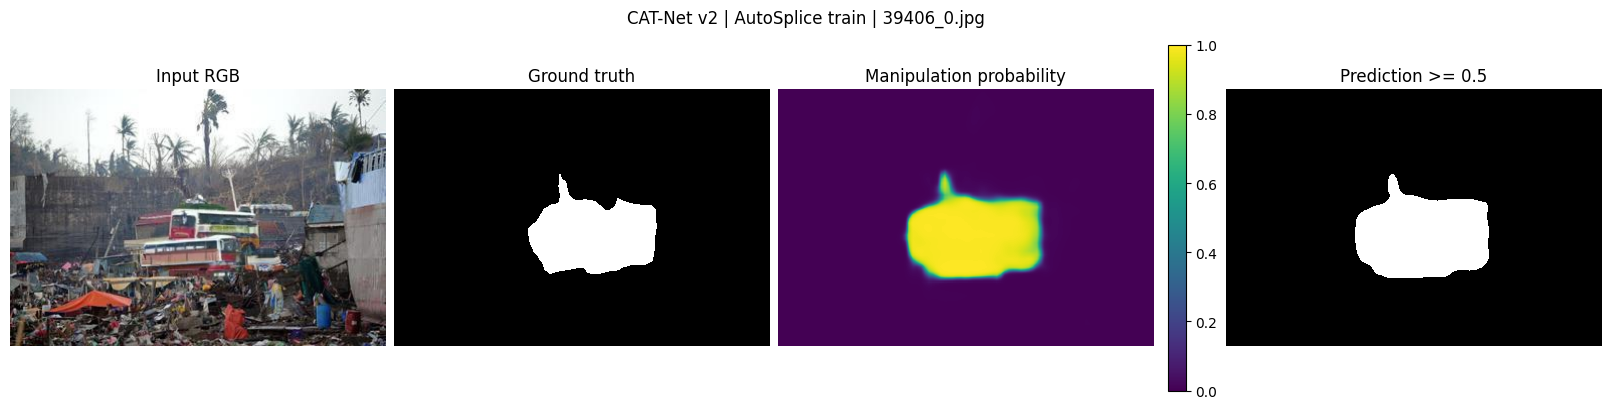

In [38]:
threshold = 0.5
prediction = (probability >= threshold).astype(np.uint8)

print("정답 조작 영역 비율:", float(mask.mean()))
print("예측 조작 영역 비율:", float(prediction.mean()))

fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)

axes[0].imshow(rgb)
axes[0].set_title("Input RGB")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[1].set_title("Ground truth")

heatmap = axes[2].imshow(probability, cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
axes[2].set_title("Manipulation probability")
fig.colorbar(heatmap, ax=axes[2], fraction=0.046, pad=0.04)

axes[3].imshow(prediction, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[3].set_title(f"Prediction >= {threshold}")

for ax in axes:
    ax.axis("off")

fig.suptitle(f"CAT-Net v2 | AutoSplice train | {image_path.name}")
plt.show()

## Metric

In [39]:
from scripts import evaluation

tp, fp, fn, tn = evaluation.confusion_counts(mask, prediction)

f1_score = evaluation.pixel_f1(tp, fp, fn)
iou_score = evaluation.iou(tp, fp, fn)

print("평가 이미지:", image_path.name)
print("분할:", sample["split"])
print("임계값:", threshold)
print("평가 크기(H, W):", mask.shape)
print("TP:", tp, "FP:", fp, "FN:", fn, "TN:", tn)
print("전체 픽셀 수:", tp + fp + fn + tn)
print("Pixel F1:", f"{f1_score:.6f}" if f1_score is not None else "계산 불가: 분모가 0임.")
print("IoU:", f"{iou_score:.6f}" if iou_score is not None else "계산 불가: 분모가 0임.")

평가 이미지: 39406_0.jpg
분할: train
임계값: 0.5
평가 크기(H, W): (256, 374)
TP: 8105 FP: 1659 FN: 16 TN: 85964
전체 픽셀 수: 95744
Pixel F1: 0.906346
IoU: 0.828732


- 각 픽셀에 대해서 FP 가 높게 나왔는데, 사실 당연한 결과로 생각됨.
    - Cat-net이 예측시 mask 범위보다 더 넓은 범위를 조작으로 판단함.
    - 이는 조작 이미지가 실제로 mask 범위보다 넓은 범위를 조작했을 가능성이 큼(자연스러운 합성을 위해)
    - 따라서 FP 가 높게 나오는 것보다 TP와 FN이 줄어드는 것으로 평가하는게 옳다고 생각됨.
    - 또는 전이학습 or 파인튜닝 시 FP 또한 줄일 수 있을까 궁금하기도 함.
 